センサからtime-intervalの変化をランダムにするかしないか
と
intervalに冗長性を持たせた時
の２つの手法でのスループットの違い

ノード数は20固定

## 1. ライブラリの読み込み

解析と可視化に必要なライブラリを読み込みます。

In [2]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import japanize_matplotlib
import pandas as pd
import yaml

## 2. 入出力先設定

ログの入力先と、生成するPDFの保存先を設定します。必要に応じてこのセルだけ編集してください。

In [9]:
# ログパス
# ログルートとバックオフごとのフォルダー名を対応付ける
BACKOFF_ROOT_DIR = Path("../data/")
BACKOFF_FOLDER_MAP = {
    "gauss*1" : "pim_20260502_002226_gauss_1",
    "gauss*2" : "pim_20260502_010200_gauss_2",
    "gauss*3" : "pim_20260502_010739_gauss_3",
    "random*1" : "pim_20260502_002824_random_1",
    "random*2" : "pim_20260502_011234_random_2",
    "random*3" : "pim_20260502_011838_random_3",
}
TARGET_NODES = [20]
TARGET_BACKOFF = 16384

# PDF出力先
OUTPUT_DIR = Path("img/paper")
THROUGHPUT_PER_NODE_BPS_PDF = OUTPUT_DIR / "throughput_per_node_bps_comparison_gauss_random.pdf"

## 3. 解析コード

データの取りうる値をgauss/randomで変化させたときの **1ノードあたりスループット** を計算します。

In [10]:
def load_events(path: Path) -> pd.DataFrame:
    """events/evens TSVを読み込み、主要列を数値・文字列へ整形する。"""
    df = pd.read_csv(path, sep="\t")
    df["time_tu"] = pd.to_numeric(df["time_tu"], errors="coerce")
    df["round"] = pd.to_numeric(df["round"], errors="coerce").astype(int)
    df["event"] = df["event"].astype(str)
    df["result"] = df["result"].astype(str)
    return df


def load_config(config_path: Path) -> dict:
    """設定ファイルを読み込む。"""
    with config_path.open("r", encoding="utf-8") as f:
        return yaml.safe_load(f)


def parse_detail_fields(detail: str) -> dict:
    """detail文字列を key=value 形式の辞書へ変換する。"""
    out = {}
    for item in str(detail).split(","):
        part = item.strip()
        if "=" not in part:
            continue
        key, value = part.split("=", 1)
        out[key.strip()] = value.strip()
    return out


def find_events_file(folder: Path, num_nodes: int) -> Path:
    """フォルダー内の evens/events TSV を返す。"""
    for candidate in (folder / f"evens_{num_nodes}.tsv", folder / f"events_{num_nodes}.tsv"):
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"evens_{num_nodes}.tsv / events_{num_nodes}.tsv が見つかりません: {folder}")


def iter_backoff_event_files(
    root_dir: Path,
    backoff_folder_map: dict,
    target_nodes: list[int],
) -> list[tuple]:
    """バックオフ時間・ノード数・パスの組を返す。"""
    files = []
    for method, folder_name in backoff_folder_map.items():
        folder = root_dir / folder_name
        for nodes in target_nodes:
            events_path = find_events_file(folder, nodes)
            files.append((nodes, method, events_path))
    return sorted(files, key=lambda x: (x[0], x[1]))


def summarize_backoff(root_dir: Path, backoff_folder_map: dict, target_nodes: list[int]) -> pd.DataFrame:
    """gauss/randomごとの衝突率と1ノードあたりスループット(bps)を集計して返す。"""
    event_files = iter_backoff_event_files(root_dir, backoff_folder_map, target_nodes)
    if not event_files:
        raise FileNotFoundError(
            f"evens_N.tsv / events_N.tsv が見つかりません: {root_dir}"
        )

    rows = []
    data_bits = None
    tu_sec = None
    for nodes, method, events_path in event_files:
        folder_config = events_path.parent / "config.yaml"
        if data_bits is None or tu_sec is None:
            config = load_config(folder_config)
            data_bits = float(config["data_bits"])
            tu_sec = float(config["tu"])
        elif folder_config.exists():
            config = load_config(folder_config)
            current_data_bits = float(config["data_bits"])
            current_tu_sec = float(config["tu"])
            if current_data_bits != data_bits or current_tu_sec != tu_sec:
                raise ValueError(f"config.yaml の内容がフォルダー間で異なります: {folder_config}")

        events = load_events(events_path)
        if events.empty:
            continue

        successes = int((events["event"] == "rx_success").sum())
        collision_rows = events[events["event"] == "collision"]

        collision_packets = 0
        for detail in collision_rows["detail"]:
            fields = parse_detail_fields(detail)
            try:
                collision_packets += int(float(fields.get("count", "1")))
            except ValueError:
                collision_packets += 1

        attempts = successes + collision_packets
        collision_rate = (collision_packets / attempts) if attempts > 0 else 0.0

        round_last_tu = events.groupby("round")["time_tu"].max()
        num_rounds = int(round_last_tu.shape[0])
        avg_round_tu = float(round_last_tu.mean()) if num_rounds > 0 else 0.0
        avg_round_sec = avg_round_tu * tu_sec
        avg_successes_per_round = (successes / num_rounds) if num_rounds > 0 else 0.0

        total_throughput_bps = (
            (avg_successes_per_round * data_bits / avg_round_sec)
            if avg_round_sec > 0
            else 0.0
        )
        throughput_per_node_bps = (total_throughput_bps / nodes) if nodes > 0 else 0.0

        rows.append(
            {
                "nodes": nodes,
                "method": method,
                "collisions": int(collision_rows.shape[0]),
                "successes": successes,
                "collision_rate": collision_rate,
                "total_throughput_bps": total_throughput_bps,
                "throughput_per_node_bps": throughput_per_node_bps,
                "file": events_path.name,
            }
        )

    return pd.DataFrame(rows).sort_values(["method", "nodes"]).reset_index(drop=True)


def plot_throughput_per_node_bps(df: pd.DataFrame, output_pdf: Path, backoff_folder_map: dict) -> None:
    """gauss/random ごとの1ノードあたりスループット(bps)をPDFに出力する。"""
    fig, ax = plt.subplots(figsize=(8, 5))
    for method in backoff_folder_map.keys():
        subset = df[df["method"] == method]
        if subset.empty:
            continue
        ax.bar([method], subset["throughput_per_node_bps"].values, label=method)
    
    ax.set_title("Throughput Per Node (bps): Gauss vs Random")
    ax.set_ylabel("Throughput Per Node (bps)")
    ax.grid(alpha=0.3, axis='y')
    ax.legend()

    output_pdf.parent.mkdir(parents=True, exist_ok=True)
    with PdfPages(output_pdf) as pdf:
        pdf.savefig(fig, bbox_inches="tight")
    plt.close(fig)

# 4. 実効

In [11]:
result = summarize_backoff(BACKOFF_ROOT_DIR, BACKOFF_FOLDER_MAP, TARGET_NODES)

# plot_throughput_per_node_bps(result, THROUGHPUT_PER_NODE_BPS_PDF, BACKOFF_FOLDER_MAP)

print("gauss/random比較解析が完了しました。")
print(f"log root: {BACKOFF_ROOT_DIR}")
# print(f"throughput per node PDF: {THROUGHPUT_PER_NODE_BPS_PDF}")
print()
print(f"=== 解析結果 (nodes={TARGET_NODES}) ===")
display(result[["nodes", "method", "collision_rate", "throughput_per_node_bps"]])

gauss/random比較解析が完了しました。
log root: ../data

=== 解析結果 (nodes=[20]) ===


,nodes,method,collision_rate,throughput_per_node_bps
0,20,gauss*1,0.228968,165.575351
1,20,gauss*2,0.240350,161.803692
2,20,gauss*3,0.244662,159.576663
3,20,random*1,0.239175,163.359274
4,20,random*2,0.246606,160.372584
5,20,random*3,0.249673,158.302074


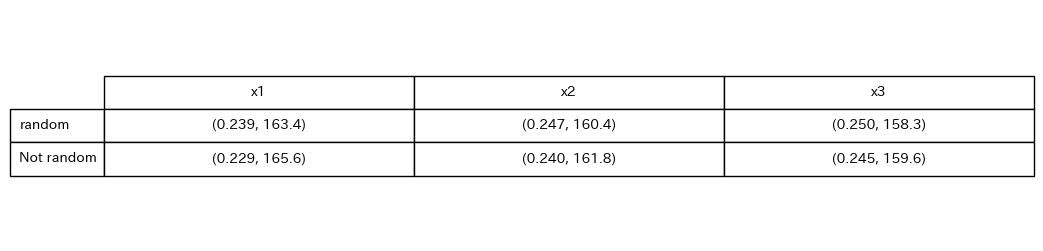

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# データ作成（そのままコピペでOK）
data = [
    [20, "random*1", 0.239175, 163.359274],
    [20, "random*2", 0.246606, 160.372584],
    [20, "random*3", 0.249673, 158.302074],
    [20, "Not random*1", 0.228968, 165.575351],
    [20, "Not random*2", 0.240350, 161.803692],
    [20, "Not random*3", 0.244662, 159.576663],
]

df = pd.DataFrame(data, columns=[
    "nodes", "method", "collision_rate", "throughput"
])

# method を分解
df[["type", "mult"]] = df["method"].str.split("*", expand=True)

# 表用データ作成
rows = ["random", "Not random"]
cols = ["x1", "x2", "x3"]

table_data = []
for r in rows:
    row_data = []
    for i in range(1, 4):
        row = df[(df["type"] == r) & (df["mult"] == str(i))].iloc[0]
        text = f"({row.collision_rate:.3f}, {row.throughput:.1f})"
        row_data.append(text)
    table_data.append(row_data)

# 描画
fig, ax = plt.subplots(figsize=(10, 3))
ax.axis('off')

table = ax.table(
    cellText=table_data,
    rowLabels=rows,
    colLabels=cols,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 2.0)

# PDF保存
plt.savefig(THROUGHPUT_PER_NODE_BPS_PDF, bbox_inches='tight')